# Import all the import lib

In [163]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Data load


In [164]:
df = pd.read_csv('Food_Delivery_Times.csv')

Data inspection

In [165]:
df.head()

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


In [166]:
df.isnull().sum()

,0
Order_ID,0
Distance_km,0
Weather,30
Traffic_Level,30
Time_of_Day,30
Vehicle_Type,0
Preparation_Time_min,0
Courier_Experience_yrs,30
Delivery_Time_min,0


# Target columns distribution

In [167]:
df['Delivery_Time_min'].skew()
# sns.histplot(df['Delivery_Time_min'], kde=True)

np.float64(0.5072511816152696)

<Axes: xlabel='Delivery_Time_min', ylabel='Count'>

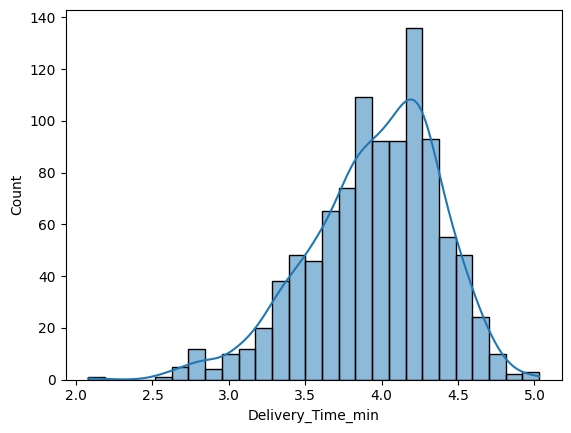

In [168]:
df['Delivery_Time_min'] = df['Delivery_Time_min'].apply(np.log)
sns.histplot(df['Delivery_Time_min'], kde = True)

In [169]:
df['Delivery_Time_min'].skew()

np.float64(-0.6215115869804703)

# Split columns  x and y

In [170]:
df.drop('Order_ID', axis = 1, inplace = True)
X = df.drop('Delivery_Time_min', axis=1)
y = df['Delivery_Time_min']

In [173]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Step 7: Preprocessing with Pipeline

### What is a Pipeline?
A pipeline is a **chain of steps** that run one after another.

> 🏭 **Real-life example:** A factory assembly line. Raw material enters → step 1 → step 2 → step 3 → finished product.

Our pipeline will do:
1. **Fill missing values** (Imputer)
2. **Convert text to numbers** (OneHotEncoder)
3. **Train the model**

### Why use a Pipeline?
| Without Pipeline | With Pipeline |
|---|---|
| Many separate cells for cleaning and encoding | One clean object |
| Test data can leak into preprocessing | No leakage |
| New data needs manual encoding | Just call `.predict()` |
| Hard to save and deploy | Save in one file |

### Define the column groups
Text columns and number columns need different treatment.

In [172]:
cat_cols = X_train.select_dtypes(include=['object', 'string']).columns.tolist()
num_cols = X_train.select_dtypes(include='number').columns.tolist()

print('Categorical:', cat_cols)
print('Numerical  :', num_cols)

Categorical: ['Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type']
Numerical  : ['Distance_km', 'Preparation_Time_min', 'Courier_Experience_yrs']


In one line: the Pipeline cleans a column in steps (fill, then convert), and the ColumnTransformer sends each column to the right Pipeline and joins the results.

### Build the preprocessor
- **Text columns:** fill missing with most frequent value → One-Hot Encode
- **Number columns:** fill missing with median

`ColumnTransformer` applies the right steps to the right columns.

`handle_unknown='ignore'` means: if a new category appears later, do not crash.

## Step 8: Decision Tree 🌳 (for comparison)

A Decision Tree asks Yes/No questions step by step.

> *Is distance > 10 km?* → Yes → *Is traffic high?* → Yes → predict 80 minutes.

It is easy to understand, but **one tree can overfit** (memorize the training data).

We put the preprocessor and the model together in one Pipeline.

### Evaluate Decision Tree
We check **train and test** scores. If train is much higher than test, the model is overfitting.

## Step 9: Random Forest 🌲 (main model)

A Random Forest is **many decision trees working together**.

1. It builds many trees (here 100).
2. Each tree trains on a random sample of rows and columns.
3. Each tree makes its own prediction.
4. The forest **averages** all predictions.

> 💡 **Real-life example:** Ask 1 friend for movie advice → can be wrong. Ask 100 friends and take the average → much more reliable.

### Evaluate Random Forest

### See predictions side by side
First 10 test orders: actual time vs what each model predicted.

## Step 12: Predict a new order (the Pipeline advantage 🎉)

We give **raw data** directly. No manual encoding, no manual filling of missing values. The pipeline does everything.

### Save the model
The whole pipeline (cleaning + encoding + model) is saved in **one file**. You can load it later, for example in a FastAPI app.